In [67]:
%pip install category_encoders

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import category_encoders as ce
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

# Preprocessing

In [2]:
data = pd.read_csv("data_saudi_used_cars.csv")
data.head()

,Type,Region,Make,Gear_Type,Origin,Options,Year,Engine_Size,Mileage,Negotiable,Price
0,Corolla,Abha,Toyota,Manual,Saudi,Standard,2013,1.4,421000,True,0
1,Yukon,Riyadh,GMC,Automatic,Saudi,Full,2014,8.0,80000,False,120000
2,Range Rover,Riyadh,Land Rover,Automatic,Gulf Arabic,Full,2015,5.0,140000,False,260000
3,Optima,Hafar Al-Batin,Kia,Automatic,Saudi,Semi Full,2015,2.4,220000,False,42000
4,FJ,Riyadh,Toyota,Automatic,Saudi,Full,2020,4.0,49000,True,0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5624 entries, 0 to 5623
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Type         5624 non-null   object 
 1   Region       5624 non-null   object 
 2   Make         5624 non-null   object 
 3   Gear_Type    5624 non-null   object 
 4   Origin       5624 non-null   object 
 5   Options      5624 non-null   object 
 6   Year         5624 non-null   int64  
 7   Engine_Size  5624 non-null   float64
 8   Mileage      5624 non-null   int64  
 9   Negotiable   5624 non-null   bool   
 10  Price        5624 non-null   int64  
dtypes: bool(1), float64(1), int64(3), object(6)
memory usage: 445.0+ KB


In [4]:
data.describe()

,Year,Engine_Size,Mileage,Price
count,5624.000000,5624.000000,5.624000e+03,5624.000000
mean,2014.101885,3.295430,1.509234e+05,53074.058144
std,5.791606,1.515108,3.828360e+05,70155.340614
min,1963.000000,1.000000,1.000000e+02,0.000000
25%,2012.000000,2.000000,3.800000e+04,0.000000
50%,2016.000000,3.000000,1.030000e+05,36500.000000
75%,2018.000000,4.500000,1.960000e+05,72932.500000
max,2022.000000,9.000000,2.000000e+07,850000.000000


In [5]:
# Check for missing values in the entire data frame
data.isnull().sum()

,0
Type,0
Region,0
Make,0
Gear_Type,0
Origin,0
Options,0
Year,0
Engine_Size,0
Mileage,0
Negotiable,0


In [6]:
# Find duplicate rows
duplicate_rows = data.duplicated()

# Display the duplicate rows
data[duplicate_rows]

,Type,Region,Make,Gear_Type,Origin,Options,Year,Engine_Size,Mileage,Negotiable,Price
953,Rio,Riyadh,Kia,Automatic,Saudi,Standard,2016,1.4,270000,False,25000
4646,Sonata,Jeddah,Hyundai,Automatic,Saudi,Standard,2020,2.4,100,False,72910
4933,Tucson,Dammam,Hyundai,Automatic,Saudi,Standard,2016,2.0,155000,False,45000
5267,Camry,Riyadh,Toyota,Automatic,Saudi,Full,2013,2.5,185000,True,0


In [7]:
# Double check duplicated rows total
data.duplicated().sum()

np.int64(4)

In [8]:
# Drop duplicated rows
data = data.drop_duplicates()

In [9]:
# Check negotiable records
print(data['Negotiable'].value_counts())

# Check zero prices
print("Zero prices:", (data['Price'] == 0).sum())

Negotiable
False    3825
True     1795
Name: count, dtype: int64
Zero prices: 1796


In [10]:
# Keep only records with valid positive prices
data = data[data['Price'] > 0].copy()

# Remove Negotiable because it is derived from Price
data = data.drop(columns=['Negotiable'])

Car listed as 0 is not being sold for free, rather it is negotiated with buyer from seller. As such including price 0 will skew the model. It is reccommended to remove 0 from both business and data side as price = 0 does not mean free and will skew the model.

In [60]:
# Check unique values in categorical columns
catg_cols = data.select_dtypes(
    include=['object', 'category']).columns

for col in catg_cols:
  print(f"\n{col}:")
  print(data[col].value_counts().head(10))


Type:
Type
Camry           149
Land Cruiser    148
Accent          147
Hilux           118
Sonata          115
Elantra         104
Taurus          102
Tahoe           100
Yukon            92
Corolla          82
Name: count, dtype: int64

Region:
Region
Riyadh       1613
Dammam        748
Jeddah        545
Al-Medina     124
Qassim        112
Al-Ahsa       110
Makkah         87
Aseer          87
Taef           53
Tabouk         51
Name: count, dtype: int64

Make:
Make
Toyota       887
Hyundai      511
Ford         346
Chevrolet    296
Nissan       252
Kia          185
Mercedes     173
GMC          166
Lexus        146
Mazda         92
Name: count, dtype: int64

Gear_Type:
Gear_Type
Automatic    3413
Manual        404
Name: count, dtype: int64

Origin:
Origin
Saudi          2887
Gulf Arabic     495
Other           419
Unknown          16
Name: count, dtype: int64

Options:
Options
Full         1472
Standard     1319
Semi Full    1026
Name: count, dtype: int64


In [74]:
for col in catg_cols:
  print(f"{col}: {data[col].nunique()} unique categories")

Type: 320 unique categories
Region: 27 unique categories
Make: 56 unique categories
Gear_Type: 2 unique categories
Origin: 4 unique categories
Options: 3 unique categories


In [12]:
# Check numerical columns
num_cols = data.select_dtypes(include=np.number).columns

data[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Year,3824.0,2014.851203,5.110916,1963.0,2013.0,2016.0,2018.0,2021.0
Engine_Size,3824.0,3.181119,1.458832,1.0,2.0,2.7,4.0,9.0
Mileage,3824.0,142621.105126,378394.151463,100.0,48000.0,103000.0,183000.0,20000000.0
Price,3824.0,78019.245031,72748.182183,1.0,35000.0,58000.0,94250.0,850000.0


In [13]:
# Check invalid values in numerical columns

print("Invalid year:", (data['Year'] <= 0).sum())
print("Invalid mileage:", (data['Mileage'] <= 0).sum())
print("Invalid engine size:", (data['Engine_Size'] <= 0).sum())

Invalid year: 0
Invalid mileage: 0
Invalid engine size: 0


# EDA

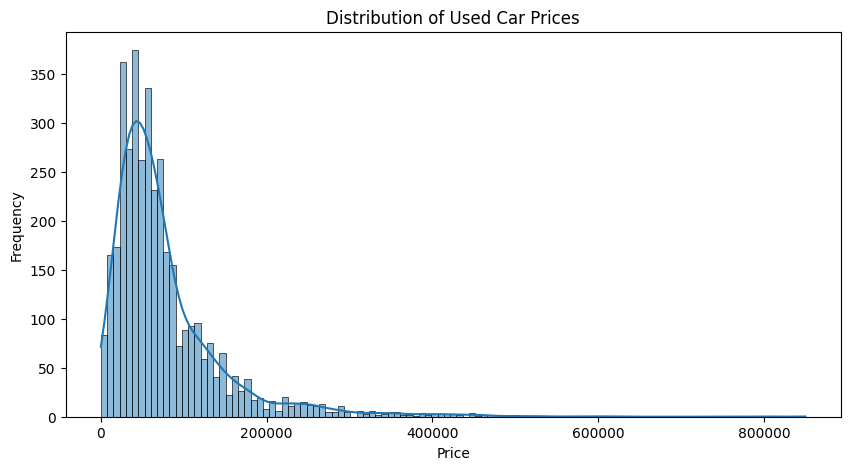

In [14]:
# Distribution of used car prices
plt.figure(figsize=(10, 5))

sns.histplot(data['Price'], kde=True)
plt.title('Distribution of Used Car Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

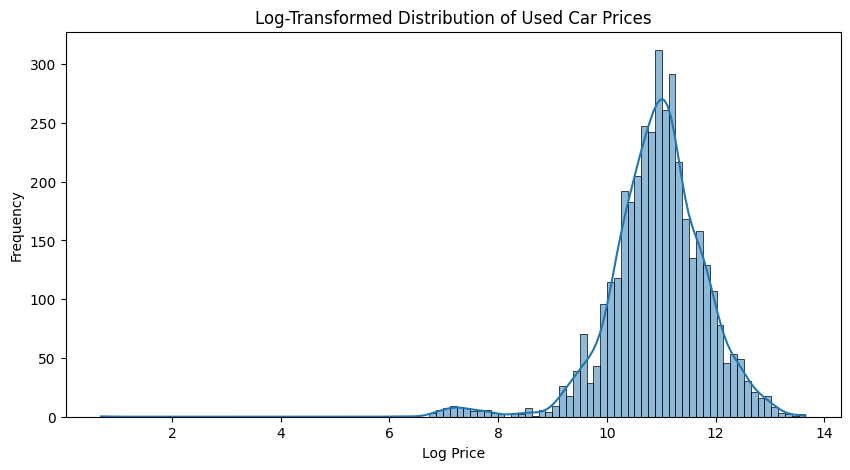

In [15]:
# Plotting Log-Transformed Price
plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(data['Price']), kde=True)
plt.title('Log-Transformed Distribution of Used Car Prices')
plt.xlabel('Log Price')
plt.ylabel('Frequency')
plt.show()

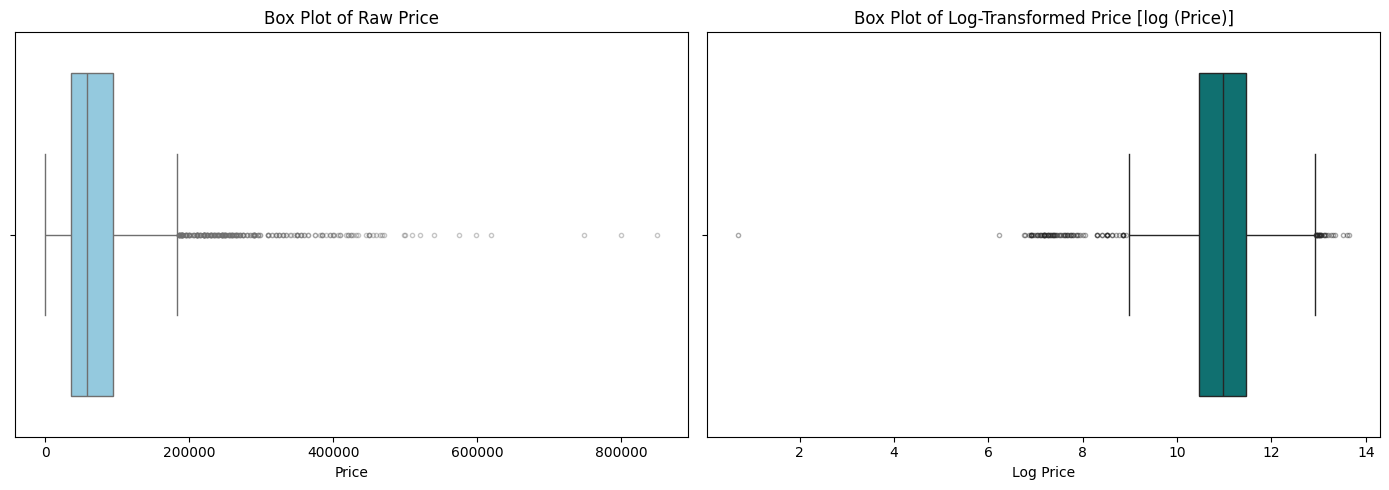

In [16]:
# Create side-by-side boxplots: Raw Price vs. Log-Transformed Price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Raw Price Boxplot
sns.boxplot(x=data['Price'], ax=axes[0], color='skyblue', flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4})
axes[0].set_title('Box Plot of Raw Price')
axes[0].set_xlabel('Price')

# 2. Log-Transformed Price Boxplot
sns.boxplot(x=np.log1p(data['Price']), ax=axes[1], color='teal', flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4})
axes[1].set_title('Box Plot of Log-Transformed Price [log (Price)]')
axes[1].set_xlabel('Log Price')

plt.tight_layout()
plt.show()

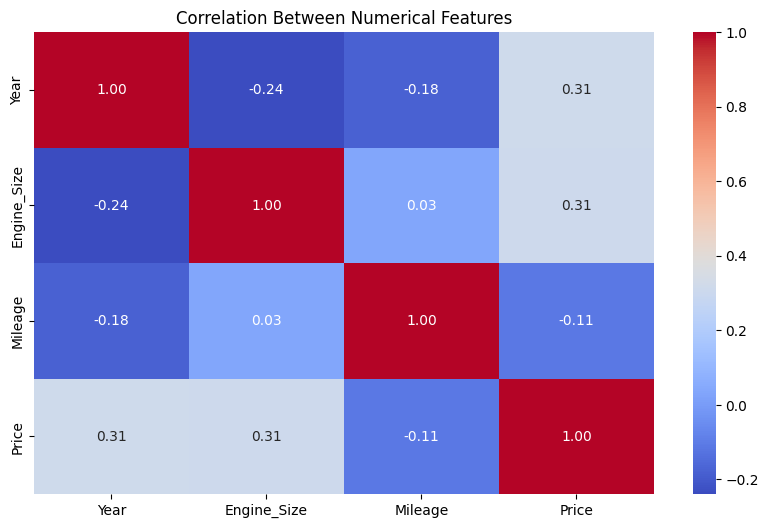

In [17]:
plt.figure(figsize=(10, 6))

sns.heatmap(data[num_cols].corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Between Numerical Features')
plt.show()

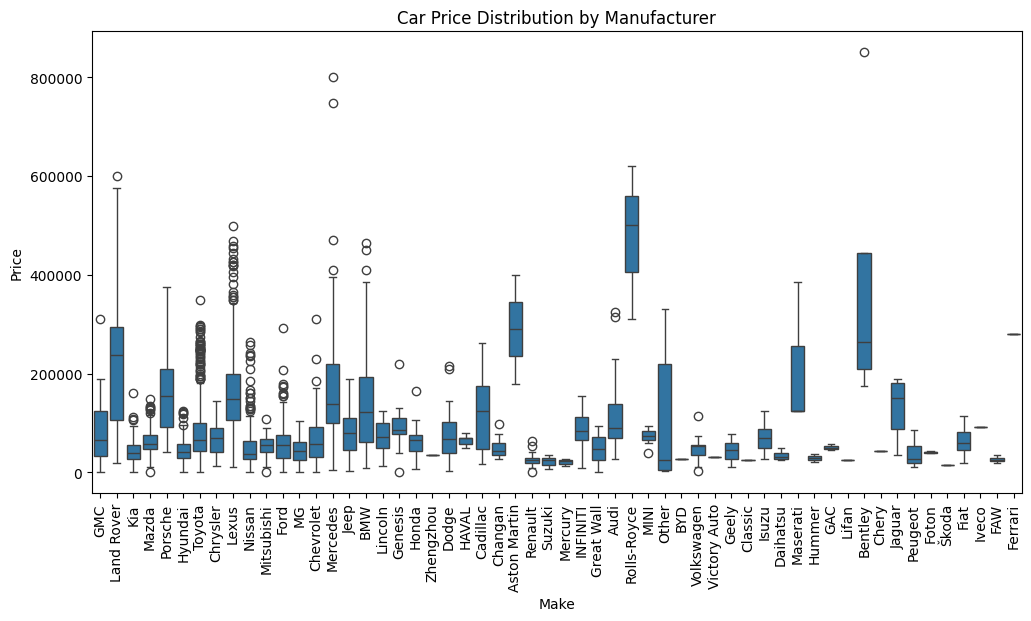

In [18]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data,
    x='Make',
    y='Price'
)

plt.xticks(rotation=90)
plt.title('Car Price Distribution by Manufacturer')
plt.show()

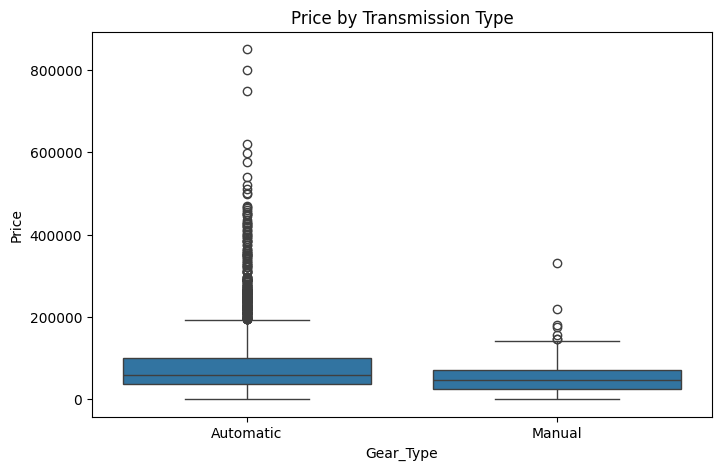

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x='Gear_Type',
    y='Price'
)

plt.title('Price by Transmission Type')
plt.show()

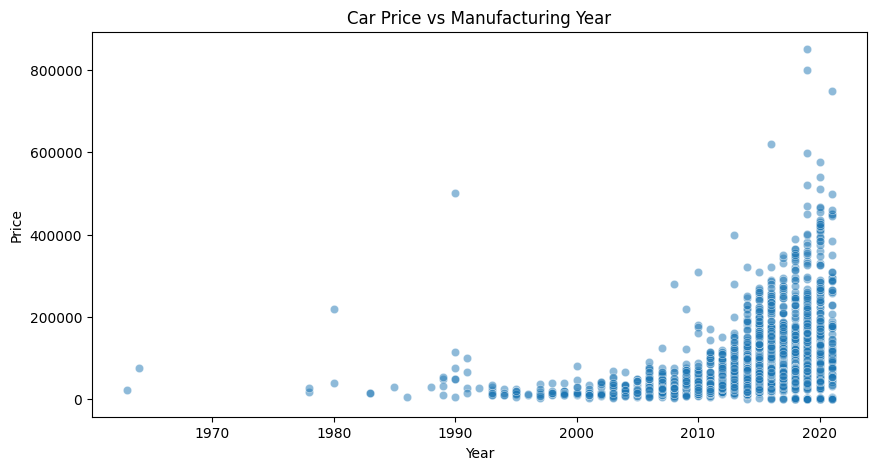

In [20]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=data,
    x='Year',
    y='Price',
    alpha=0.5
)

plt.title('Car Price vs Manufacturing Year')
plt.show()

In [21]:
# Filter and inspect cars manufactured before 1990
vintage_cars = data[data['Year'] < 1990]

print(f"Total cars manufactured before 1980: {len(vintage_cars)}")
display(vintage_cars[['Make', 'Type', 'Year', 'Mileage', 'Engine_Size', 'Gear_Type', 'Origin', 'Options', 'Price']])

Total cars manufactured before 1980: 15


,Make,Type,Year,Mileage,Engine_Size,Gear_Type,Origin,Options,Price
62,Mercedes,SEL,1986,500000,3.0,Automatic,Saudi,Full,5500
306,Toyota,Land Cruiser Pickup,1983,2580,1.5,Manual,Saudi,Standard,15000
663,Other,Other,1980,2500,2.4,Manual,Other,Standard,220000
1419,Toyota,Land Cruiser,1988,195000,4.0,Manual,Saudi,Semi Full,30000
2262,Chevrolet,Impala,1964,100000,1.2,Automatic,Other,Full,75000
2753,BMW,The 7,1989,67000,5.0,Automatic,Other,Full,48000
3082,Toyota,Land Cruiser 70,1978,400000,4.0,Manual,Saudi,Standard,18000
3129,Toyota,Land Cruiser 70,1983,300000,3.8,Manual,Saudi,Standard,14000
3143,BMW,The 7,1989,176000,5.0,Automatic,Other,Full,33000
3238,Nissan,Patrol,1978,30000,4.0,Manual,Saudi,Standard,28000


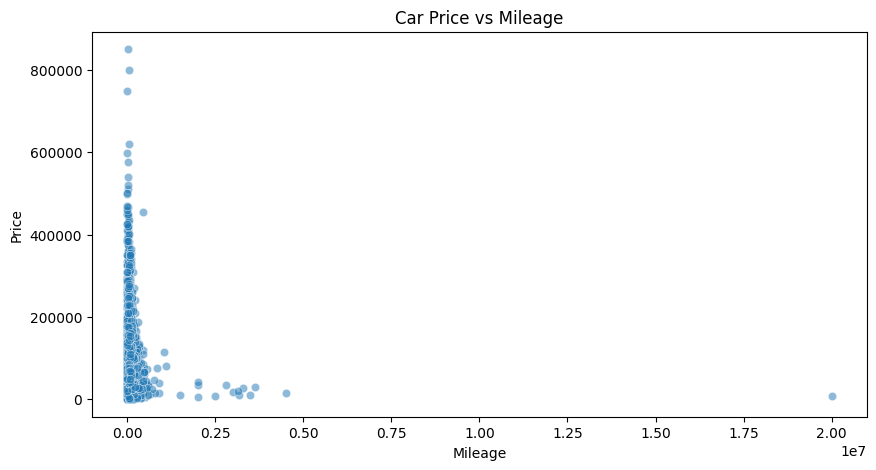

In [22]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=data,
    x='Mileage',
    y='Price',
    alpha=0.5
)

plt.title('Car Price vs Mileage')
plt.show()

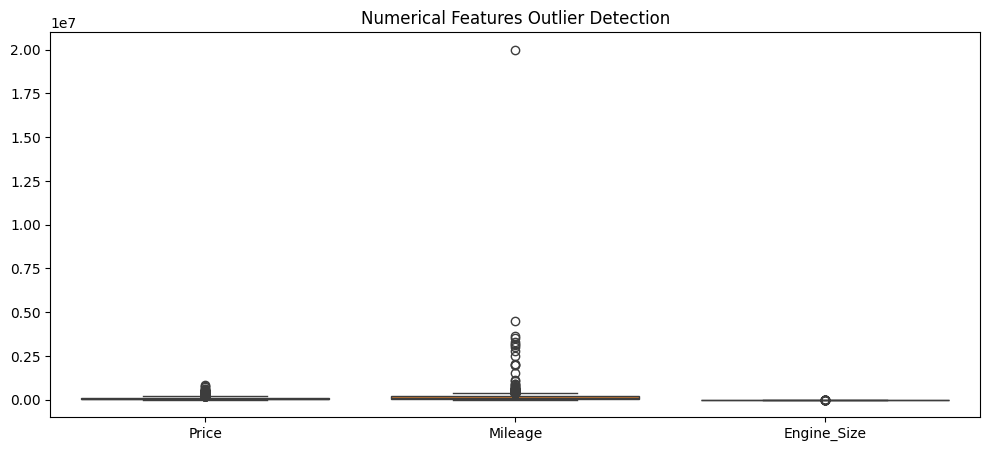

In [23]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=data[['Price', 'Mileage', 'Engine_Size']])

plt.title('Numerical Features Outlier Detection')
plt.show()

In [24]:
for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[col] < lower_bound) |
        (data[col] > upper_bound)
    ]

    print(f'{col}: {len(outliers)} potential outliers')

Year: 184 potential outliers
Engine_Size: 30 potential outliers
Mileage: 131 potential outliers
Price: 259 potential outliers


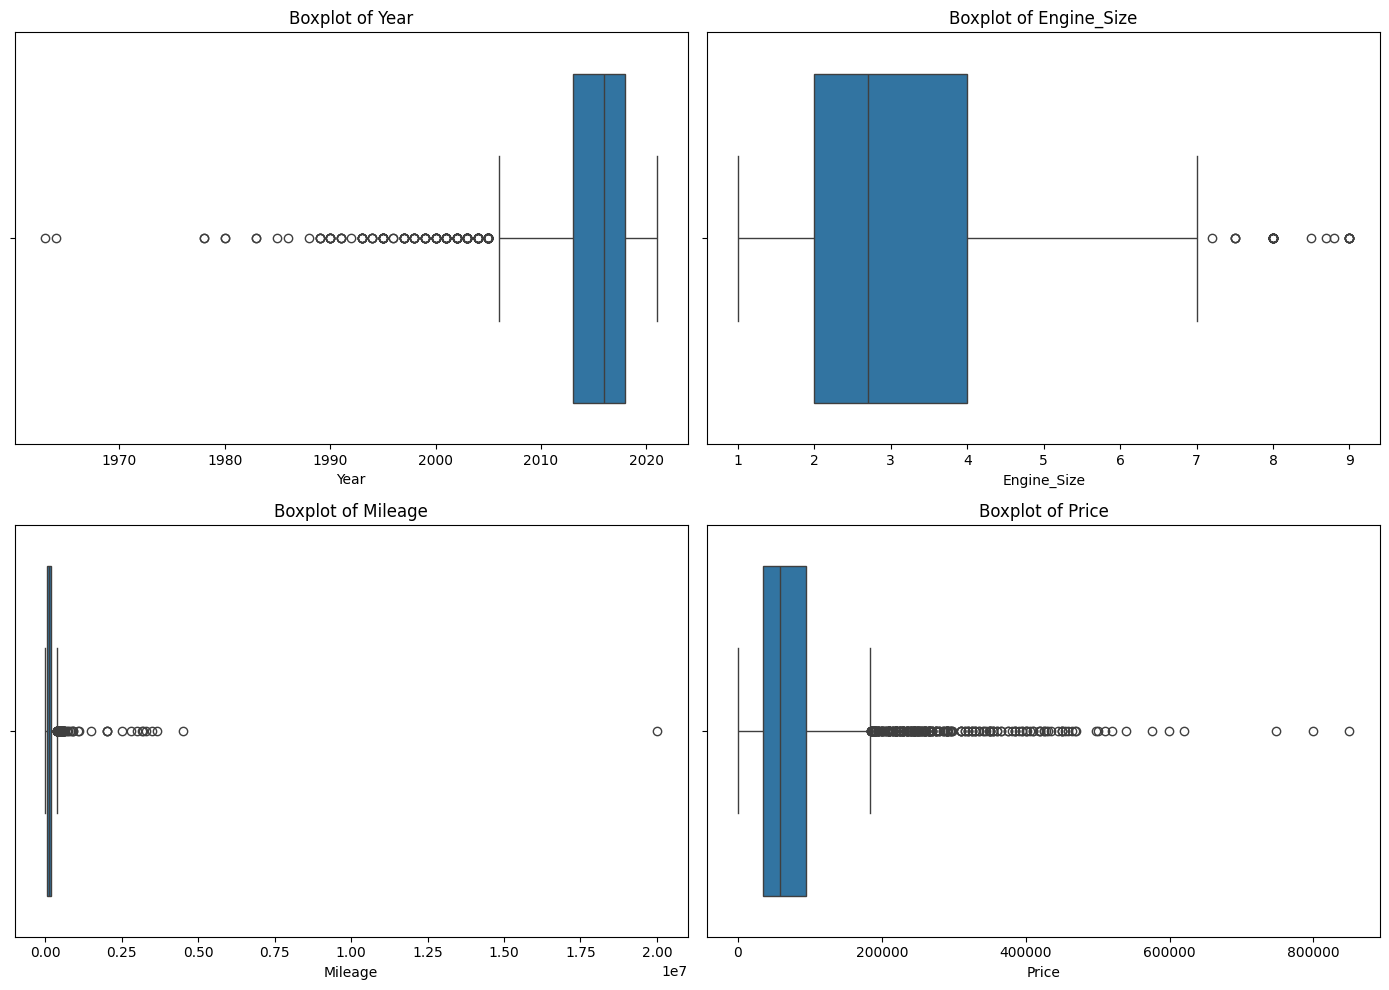

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(num_cols, axes.flatten()):
    sns.boxplot(x=data[col], ax=ax)
    ax.set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [26]:
# Highest-priced vehicles
data.nlargest(10, 'Price')[
    ['Make', 'Type', 'Year', 'Engine_Size', 'Mileage', 'Price']]

,Make,Type,Year,Engine_Size,Mileage,Price
3513,Bentley,Bentayga,2019,6.0,13000,850000
4684,Mercedes,G,2019,4.0,39000,800000
4273,Mercedes,S,2021,3.0,2500,748000
2120,Rolls-Royce,Ghost,2016,6.0,40000,620000
4653,Land Rover,Range Rover,2019,5.0,4200,599000
3561,Land Rover,Range Rover,2020,5.0,26000,575000
3105,Land Rover,Range Rover,2020,5.0,36000,540000
2862,Land Rover,Range Rover,2019,5.6,36000,520000
2504,Land Rover,Range Rover,2020,3.0,11500,510000
3041,Rolls-Royce,Camargue,1990,6.7,5000,500000


In [27]:
# Lowest-priced vehicles
data.nsmallest(10, 'Price')[
    ['Make', 'Type', 'Year', 'Engine_Size', 'Mileage', 'Price']]

,Make,Type,Year,Engine_Size,Mileage,Price
3131,GMC,Yukon,2019,5.3,50000,1
3992,Genesis,G80,2018,3.8,170000,500
4399,Toyota,Yaris,2018,1.5,100000,850
5128,Kia,Rio,2019,1.4,55500,884
3474,Toyota,Yaris,2019,1.6,85000,950
3760,MG,5,2020,1.5,41000,988
3616,Hyundai,Elantra,2019,2.0,89000,993
1534,GMC,Yukon,2021,5.3,4000,1000
3892,Toyota,Corolla,2020,1.6,48563,1002
46,Hyundai,Elantra,2020,2.0,27000,1010


In [28]:
data[data['Price'] < 1000].sort_values('Price')

,Type,Region,Make,Gear_Type,Origin,Options,Year,Engine_Size,Mileage,Price
3131,Yukon,Jubail,GMC,Automatic,Saudi,Full,2019,5.3,50000,1
3992,G80,Riyadh,Genesis,Automatic,Other,Semi Full,2018,3.8,170000,500
4399,Yaris,Riyadh,Toyota,Automatic,Saudi,Standard,2018,1.5,100000,850
5128,Rio,Arar,Kia,Automatic,Saudi,Standard,2019,1.4,55500,884
3474,Yaris,Najran,Toyota,Automatic,Saudi,Standard,2019,1.6,85000,950
3760,5,Al-Ahsa,MG,Automatic,Saudi,Standard,2020,1.5,41000,988
3616,Elantra,Jeddah,Hyundai,Automatic,Saudi,Standard,2019,2.0,89000,993


In [29]:
data['Price'].describe(
    percentiles=[0.01, 0.025, 0.05, 0.10])

,Price
count,3824.000000
mean,78019.245031
std,72748.182183
min,1.000000
1%,1639.200000
2.5%,9500.000000
5%,14000.000000
10%,21000.000000
50%,58000.000000
max,850000.000000


In [30]:
thresholds = [500, 1000, 2000, 3000, 5000]

for threshold in thresholds:
    count = (data['Price'] < threshold).sum()
    print(f'Below SAR {threshold:,}: {count} records')

Below SAR 500: 1 records
Below SAR 1,000: 7 records
Below SAR 2,000: 46 records
Below SAR 3,000: 61 records
Below SAR 5,000: 68 records


In [107]:
# Apply the 5,000 SAR minimum threshold
data = data[data['Price'] >= 5000].copy()

# Also apply the classic car filter discussed earlier (e.g., keeping 1990 and newer)
data = data[data['Year'] >= 1990].copy()

# Apply the extreme mileage filter to drop typos (like the 20 million km record)
data = data[data['Mileage'] <= 1000000].copy()

In [108]:
current_year = 2026
data['Car_Age'] = current_year - data['Year']

In [33]:
data

,Type,Region,Make,Gear_Type,Origin,Options,Year,Engine_Size,Mileage,Price,Car_Age
1,Yukon,Riyadh,GMC,Automatic,Saudi,Full,2014,8.0,80000,120000,12
2,Range Rover,Riyadh,Land Rover,Automatic,Gulf Arabic,Full,2015,5.0,140000,260000,11
3,Optima,Hafar Al-Batin,Kia,Automatic,Saudi,Semi Full,2015,2.4,220000,42000,11
5,CX3,Abha,Mazda,Automatic,Saudi,Semi Full,2019,2.0,25000,58000,7
6,Cayenne S,Riyadh,Porsche,Automatic,Saudi,Full,2012,4.8,189000,85000,14
...,...,...,...,...,...,...,...,...,...,...,...
5616,CX9,Qassim,Mazda,Automatic,Saudi,Full,2020,2.0,9500,132000,6
5618,Suburban,Riyadh,GMC,Automatic,Saudi,Full,2006,5.3,86000,50000,20
5619,X-Trail,Jeddah,Nissan,Automatic,Saudi,Standard,2018,2.5,78794,68000,8
5621,Yukon,Dammam,GMC,Automatic,Saudi,Full,2016,5.3,48000,145000,10


In [109]:
features = [
    'Type',
    'Region',
    'Make',
    'Gear_Type',
    'Origin',
    'Options',
    'Car_Age',
    'Engine_Size',
    'Mileage']

target = 'Price'

x = data[features]
y = data[target]

In [110]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=42)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (2980, 9)
Testing data: (745, 9)


# Preprocessing

In [111]:
num_features = ['Car_Age','Engine_Size','Mileage']
onehot_features = ['Gear_Type','Origin','Options'] # Contain <5 unique values
binary_features = ['Type','Region','Make'] # Contain >10 unique values

In [112]:
numerical_transformer = StandardScaler()
onehot_transformer = OneHotEncoder(handle_unknown='ignore')
binary_transformer = ce.BinaryEncoder(handle_unknown='value')

In [113]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, num_features),
        ('onehot', onehot_transformer, onehot_features),
        ('binary', binary_transformer, binary_features)])

In [114]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Training shape:", x_train_processed.shape)
print("Testing shape:", x_test_processed.shape)

Training shape: (2980, 32)
Testing shape: (745, 32)


In [115]:
# Convert sparse matrix to dense array
if hasattr(x_train_processed, 'toarray'):
    x_train_array = x_train_processed.toarray()
else:
    x_train_array = x_train_processed

if hasattr(x_test_processed, 'toarray'):
    x_test_array = x_test_processed.toarray()
else:
    x_test_array = x_test_processed

In [116]:
feature_names = preprocessor.get_feature_names_out()

x_train_processed_df = pd.DataFrame(
    x_train_array,
    columns=feature_names,
    index=x_train.index)

x_test_processed_df = pd.DataFrame(
    x_test_array,
    columns=feature_names,
    index=x_test.index)

In [117]:
display(x_train_processed_df.head())
display(x_test_processed_df.head())

,num__Car_Age,num__Engine_Size,num__Mileage,onehot__Gear_Type_Automatic,onehot__Gear_Type_Manual,onehot__Origin_Gulf Arabic,onehot__Origin_Other,onehot__Origin_Saudi,onehot__Origin_Unknown,onehot__Options_Full,...,binary__Region_1,binary__Region_2,binary__Region_3,binary__Region_4,binary__Make_0,binary__Make_1,binary__Make_2,binary__Make_3,binary__Make_4,binary__Make_5
2374,1.926060,-0.946270,1.695822,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4024,-0.657529,-1.082197,0.102557,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5051,-0.657529,0.209114,-0.882046,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
318,-0.657529,0.413005,0.263673,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
5097,1.280162,1.704316,1.901693,1.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


,num__Car_Age,num__Engine_Size,num__Mileage,onehot__Gear_Type_Automatic,onehot__Gear_Type_Manual,onehot__Origin_Gulf Arabic,onehot__Origin_Other,onehot__Origin_Saudi,onehot__Origin_Unknown,onehot__Options_Full,...,binary__Region_1,binary__Region_2,binary__Region_3,binary__Region_4,binary__Make_0,binary__Make_1,binary__Make_2,binary__Make_3,binary__Make_4,binary__Make_5
840,0.203667,-0.470524,-0.004855,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5100,-0.011632,0.209114,0.442692,1.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
5434,-0.226931,0.413005,0.015733,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
4005,-0.872828,0.548933,-0.434499,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2126,-0.226931,-0.538487,-0.387059,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


In [118]:
print("Training shape:", x_train_processed.shape)
print("Testing shape:", x_test_processed.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training shape: (2980, 32)
Testing shape: (745, 32)
Training target shape: (2980,)
Testing target shape: (745,)


# Regression

In [119]:
baseline_model = DummyRegressor(strategy='median')

baseline_model.fit(x_train, y_train)

y_pred_baseline = baseline_model.predict(x_test)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 45750.90067114094
Baseline RMSE: 79937.84841359337
Baseline R2: -0.09644616839066522


In [122]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42)}

In [123]:
results = []
trained_models = {}

for name, model in models.items():

  pipeline = Pipeline(steps=[
  ('preprocessor', preprocessor),
  ('model', model)])

  # Train model
  pipeline.fit(x_train, y_train)

  # Predict
  y_pred = pipeline.predict(x_test)

  # Evaluate
  mae = mean_absolute_error(y_test, y_pred)
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)

  results.append({
    'Model': name,
    'MAE': mae,
    'RMSE': rmse,
    'R2': r2})

  trained_models[name] = pipeline

In [124]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='MAE',
    ascending=True
).reset_index(drop=True)

display(results_df.round(2))

,Model,MAE,RMSE,R2
0,Extra Trees,15954.10,37610.59,0.76
1,Random Forest,17673.86,40408.12,0.72
2,Gradient Boosting,21009.42,40206.97,0.72
3,Ridge Regression,32869.07,56900.17,0.44
4,Linear Regression,32874.19,56897.85,0.44


In [125]:
# Create pipeline
et_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', ExtraTreesRegressor(random_state=42, n_jobs=-1))
])

# Parameter grid
param_grid = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [None, 10, 20, 30, 40],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [1.0, 'sqrt', 0.7]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=et_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit
random_search.fit(x_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}
Best CV MAE: 16105.800259507829


In [126]:
best_model = random_search.best_estimator_

y_pred_tuned = best_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_tuned)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Extra Trees Results")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2:", round(r2, 4))

Tuned Extra Trees Results
MAE: 15300.69
RMSE: 36074.2
R2: 0.7767


In [128]:
et_model = best_model.named_steps['model']

# Get feature names after preprocessing
feature_names = best_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Extract feature importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': et_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
display(importance_df.head(10))

,Feature,Importance
0,num__Car_Age,0.229654
1,num__Engine_Size,0.116767
9,onehot__Options_Full,0.092818
2,num__Mileage,0.076399
30,binary__Make_4,0.044648
31,binary__Make_5,0.038548
27,binary__Make_1,0.035866
28,binary__Make_2,0.033369
29,binary__Make_3,0.030012
17,binary__Type_5,0.029134


In [129]:
perm = permutation_importance(
    best_model,
    x_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': x_test.columns,
    'Importance': perm.importances_mean
})

permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

display(permutation_df)

,Feature,Importance
6,Car_Age,21323.541279
2,Make,15177.852580
7,Engine_Size,13303.850055
0,Type,10827.830140
5,Options,6690.441988
8,Mileage,2610.960353
4,Origin,306.412805
1,Region,253.965652
3,Gear_Type,63.080200


In [145]:
# Get feature names after preprocessing
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

# Create feature importance dataframe
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': et_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(importance_df.head(10))

,Feature,Importance
0,num__Car_Age,0.229654
1,num__Engine_Size,0.116767
9,onehot__Options_Full,0.092818
2,num__Mileage,0.076399
30,binary__Make_4,0.044648
31,binary__Make_5,0.038548
27,binary__Make_1,0.035866
28,binary__Make_2,0.033369
29,binary__Make_3,0.030012
17,binary__Type_5,0.029134


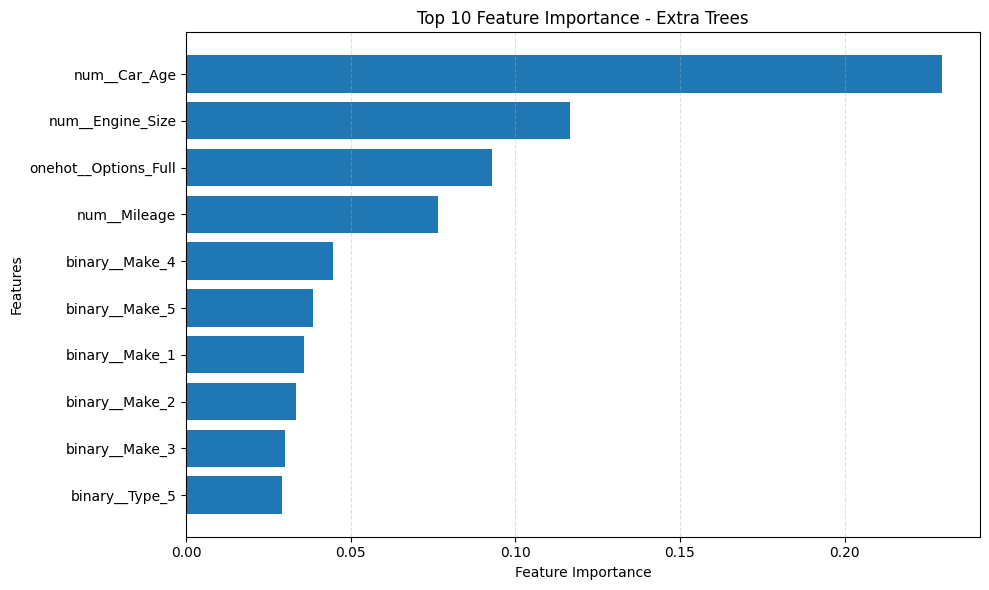

In [146]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'].head(10)[::-1],
    importance_df['Importance'].head(10)[::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 10 Feature Importance - Extra Trees')

plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [131]:
# Generate predictions
y_pred = best_model.predict(x_test)

# Create comparison dataframe
prediction_df = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

prediction_df['Error'] = (
    prediction_df['Actual Price'] -
    prediction_df['Predicted Price']
)

prediction_df['Absolute Error'] = prediction_df['Error'].abs()

display(prediction_df.head(10).round(2))

,Actual Price,Predicted Price,Error,Absolute Error
840,37000,43108.0,-6108.0,6108.0
5100,60000,61342.0,-1342.0,1342.0
5434,70000,112108.0,-42108.0,42108.0
4005,149500,149000.0,500.0,500.0
2126,53500,48651.0,4849.0,4849.0
285,35000,36614.6,-1614.6,1614.6
4442,73000,73305.0,-305.0,305.0
747,85000,79055.0,5945.0,5945.0
5421,29000,49451.8,-20451.8,20451.8
3078,69000,65984.0,3016.0,3016.0


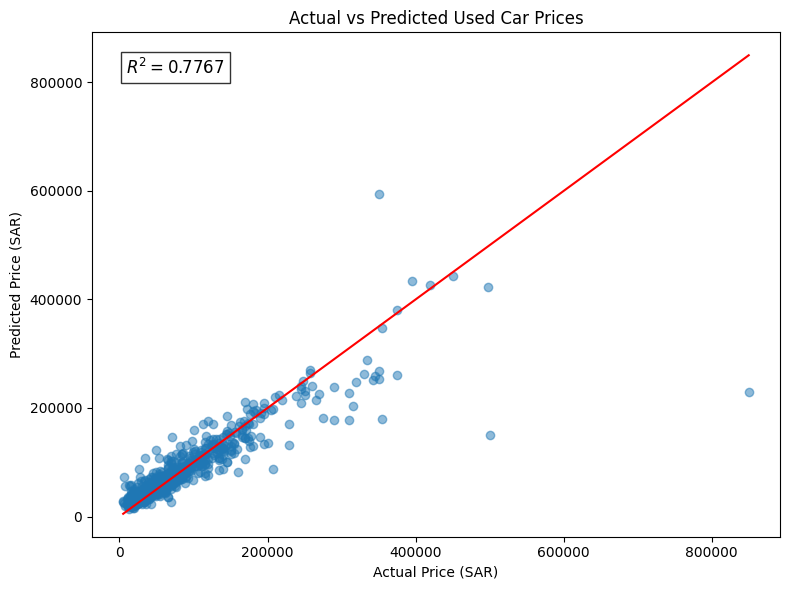

In [132]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='-',
    color = 'red')

plt.text(
    0.05, 0.95,
    f'$R^2 = {r2:.4f}$',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8))

plt.xlabel('Actual Price (SAR)')
plt.ylabel('Predicted Price (SAR)')
plt.title('Actual vs Predicted Used Car Prices')

plt.tight_layout()
plt.show()

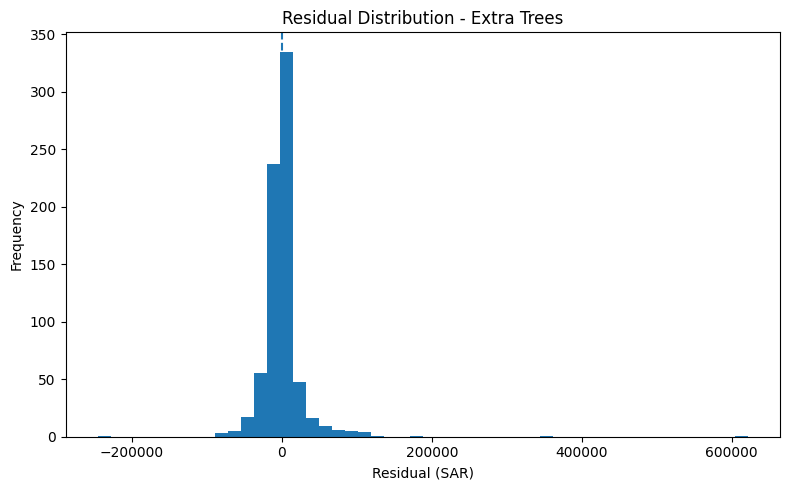

In [133]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=50)

plt.axvline(
    x=0,
    linestyle='--'
)

plt.xlabel('Residual (SAR)')
plt.ylabel('Frequency')
plt.title('Residual Distribution - Extra Trees')

plt.tight_layout()
plt.show()

In [134]:
# Sort by largest absolute prediction error
largest_errors = prediction_df.sort_values(
    by='Absolute Error',
    ascending=False)

display(largest_errors.head(10).round(2))

,Actual Price,Predicted Price,Error,Absolute Error
3513,850000,228979.0,621021.0,621021.0
3041,500000,149299.0,350701.0,350701.0
4202,350000,595234.0,-245234.0,245234.0
4996,355000,180598.0,174402.0,174402.0
556,310000,177105.0,132895.0,132895.0
2417,207000,88427.0,118573.0,118573.0
3608,375000,261375.0,113625.0,113625.0
1459,290000,178141.0,111859.0,111859.0
4058,315000,203330.0,111670.0,111670.0
5555,229000,132470.0,96530.0,96530.0


In [137]:
error_analysis = prediction_df.copy()

error_analysis['Price Range'] = pd.cut(
    error_analysis['Actual Price'],
    bins=[0, 20000, 50000, 100000, 200000, float('inf')],
    labels=[
        'Below 20K',
        '20K-50K',
        '50K-100K',
        '100K-200K',
        'Above 200K'
])

price_range_analysis = error_analysis.groupby(
    'Price Range',observed=False).agg(
    MAE=('Absolute Error', 'mean'),
    Average_Actual_Price=('Actual Price', 'mean'),
    Number_of_Cars=('Actual Price', 'count')
).reset_index()

display(price_range_analysis.round(2))

,Price Range,MAE,Average_Actual_Price,Number_of_Cars
0,Below 20K,15924.81,15241.94,62
1,20K-50K,8411.06,36328.29,235
2,50K-100K,9756.01,70602.71,266
3,100K-200K,18229.79,140079.71,138
4,Above 200K,75551.55,314500.00,44


In [139]:
error_analysis = prediction_df.copy()

error_analysis['Price Range'] = pd.cut(
    error_analysis['Actual Price'],
    bins=[0, 20000, 50000, 100000, 200000, float('inf')],
    labels=[
        'Below 20K',
        '20K-50K',
        '50K-100K',
        '100K-200K',
        'Above 200K'
    ]
)

price_range_analysis = error_analysis.groupby(
    'Price Range',
    observed=False
).agg(
    MAE=('Absolute Error', 'mean'),
    RMSE=('Error', lambda x: np.sqrt((x ** 2).mean())),
    Average_Actual_Price=('Actual Price', 'mean'),
    Average_Error=('Error', 'mean'),
    Number_of_Cars=('Actual Price', 'count')
).reset_index()

price_range_analysis['MAE_Percentage'] = (
    price_range_analysis['MAE'] /
    price_range_analysis['Average_Actual_Price'] * 100
)

display(price_range_analysis.round(2))

,Price Range,MAE,RMSE,Average_Actual_Price,Average_Error,Number_of_Cars,MAE_Percentage
0,Below 20K,15924.81,20759.26,15241.94,-15711.95,62,104.48
1,20K-50K,8411.06,13734.61,36328.29,-6624.41,235,23.15
2,50K-100K,9756.01,14763.96,70602.71,-2195.10,266,13.82
3,100K-200K,18229.79,24420.68,140079.71,8633.53,138,13.01
4,Above 200K,75551.55,131267.84,314500.00,60299.45,44,24.02


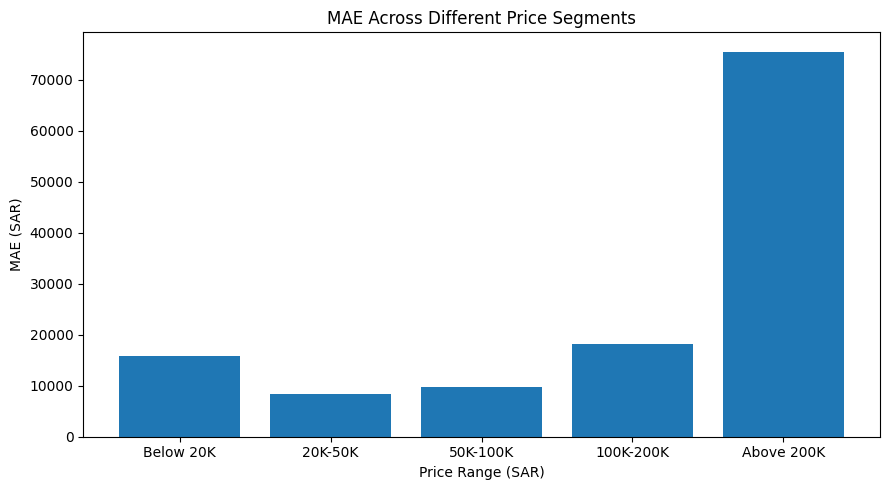

In [142]:
plt.figure(figsize=(9, 5))

plt.bar(
    price_range_analysis['Price Range'].astype(str),
    price_range_analysis['MAE']
)

plt.xlabel('Price Range (SAR)')
plt.ylabel('MAE (SAR)')
plt.title('MAE Across Different Price Segments')

plt.tight_layout()
plt.show()

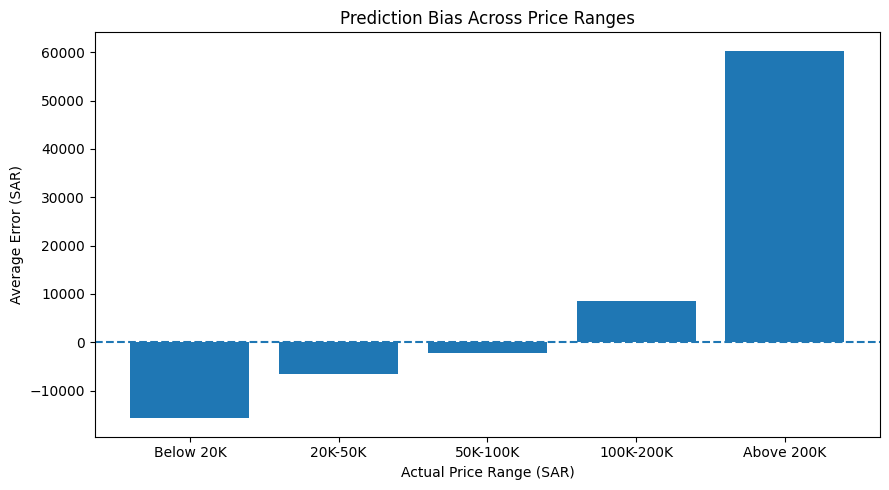

In [140]:
plt.figure(figsize=(9, 5))

plt.bar(
    price_range_analysis['Price Range'].astype(str),
    price_range_analysis['Average_Error']
)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Actual Price Range (SAR)')
plt.ylabel('Average Error (SAR)')
plt.title('Prediction Bias Across Price Ranges')

plt.tight_layout()
plt.show()

In [141]:
# Get the 10 largest prediction errors
largest_errors = prediction_df.sort_values(by='Absolute Error',ascending=False).head(10)

display(largest_errors.round(2))

,Actual Price,Predicted Price,Error,Absolute Error
3513,850000,228979.0,621021.0,621021.0
3041,500000,149299.0,350701.0,350701.0
4202,350000,595234.0,-245234.0,245234.0
4996,355000,180598.0,174402.0,174402.0
556,310000,177105.0,132895.0,132895.0
2417,207000,88427.0,118573.0,118573.0
3608,375000,261375.0,113625.0,113625.0
1459,290000,178141.0,111859.0,111859.0
4058,315000,203330.0,111670.0,111670.0
5555,229000,132470.0,96530.0,96530.0
